# Parameters identifiability

In the follow up study, we will have two phases with different experimental conditions. The experiment was designed such that each phase leads to different predictions to test the predictive power of our model, and the experimental conditions were selected because they are predicted to bring about a large enough predicted difference that we can detect.

In this notebook, we will simulate data based on our model predictions, then fit the model to see whether we can recover the parameters the way we'd expect. 

# Setting up the tasks:

In [31]:
# Import all packages and declare custom function
# General utilities:
import os 
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import warnings
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Stats
import pymc as pm
from scipy.special import logit, expit

# Custom packages:
from stabst.MarkovDecisionProcess import MDP
from stabst.TaskConfig import LimitedEnergyTask
from stabst.utils import avg_reduce_mdp, abstract2ground_value

n_samples = 1000
n_warmup = 1000
n_chains = 4
rng = np.random.default_rng(615)

def entropy(p):
    if p == 0:
        p += 0.000001
    elif p == 1:
        p -= 0.000001
    return (-p * np.log(p) - (1-p) * np.log(1 - p)) / (-0.5 * np.log(0.5) - (1-0.5) * np.log(1 - 0.5))



def preference_model(
        y: np.array,
        decision_values: np.array,
        pref_regressors: pd.DataFrame,
        subject_index: np.array,
        subject_labels: np.array      
):
    '''
    Parameters
    ----------
    y : np.array [N samples, ]
        Observed binary data (1, 0...)
    decision_values : np.array [N samples, ]
        DV to regress onto the observed data
    pref_regressors : np.array [N samples, M regressors]
        Regressor to fit participants preference for. We can have M regressors
    subject_index : np.array  [N samples, ]
        Index of the subject associated with each observation
    subject_labels : np.array  [N subjects, ]
        Single identifier of each subject
    coords : dict  
        "subject": subj_labels, 
        "coef": ["intercept", "slope"],
        The subject maps the data to each subject, the coef are for the coefficients
    b_prior_mean : Optional[float], optional
        Prior mean of each beta parameters, by default 0
    b_prior_sigma : Optional[float], optional
        Prior variance of the population level distribution of the beta, by default 2`
    s_prior_sigma : Optional[float], optional
        Prior between subjects variance, by default 2
    n_drawss : Optional[int], optional
        Number of draws for the posterior, by default 1000
    n_tuning_draws : Optional[int], optional
        Number of tuning draws, by default 1000
    Returns
    -------
    tuple[pm.Model, arviz.InferenceData]
        pm.model : pymc model object
        idata : arviz inference data
    '''
    # Get dimensions:
    n_obs = y.shape[0]
    n_groups = subject_labels.shape[0]
    n_pref = pref_regressors.shape[1]

    # Create intercept:
    intercept = np.ones(n_obs)

    # Set coordinates:
    coords = {
        "subject": subject_labels,
        "coef_intercept": ["B_intercept"],
        "coef_planning": ["B_plan"],
        "coef_pref": ["B_" + col for col in pref_regressors.columns],
        "coef_interaction": ["slope"],
    }

    # Model:
    with pm.Model(coords=coords) as planning_preferences_interaction_model:
        # Data:
        y_obs = pm.Data("y_obs", y)
        intercept = pm.Data("intercept", intercept)
        planning = pm.Data("planning", decision_values)
        preferences = pm.Data("preferences", pref_regressors)
        subj_idx = pm.Data("subj_idx", subject_index.astype("int32"))

        # Hyperpriors:
        # Intercept term
        beta_intercept = pm.Normal("beta_intercept", mu=0, sigma=2, dims="coef_intercept")
        sigma_intercept = pm.HalfNormal("sigma_intercept", sigma=2, dims="coef_intercept")
        # Planning term:
        beta_planning = pm.Normal("beta_planning", mu=0, sigma=2, dims="coef_planning")
        sigma_planning = pm.HalfNormal("sigma_planning", sigma=2, dims="coef_planning")
        # Preference terms:
        beta_pref = pm.Normal("beta_pref", mu=0, sigma=2, dims="coef_pref")
        sigma_pref = pm.HalfNormal("sigma_pref", sigma=2, dims="coef_pref")
        # Interaction term:
        beta_interaction = pm.Normal("beta_interaction", mu=0, sigma=2, dims="coef_interaction")
        sigma_interaction = pm.HalfNormal("sigma_interaction", sigma=2, dims="coef_interaction")

        # Offset parameters:
        z_intercept = pm.Normal("z_intercept", 0, 1, dims=("subject", "coef_intercept"))
        z_planning = pm.Normal("z_planning", 0, 1, dims=("subject", "coef_planning"))
        z_biases = pm.Normal("z_biases", 0, 1, dims=("subject", "coef_pref"))
        z_interaction = pm.Normal("z_interaction", 0, 1, dims=("subject", "coef_interaction"))

        # Centered parameters:
        beta_intercept_sub = pm.Deterministic("beta_intercept_sub", beta_intercept + z_intercept * sigma_intercept, 
                                              dims=("subject", "coef_intercept"))
        beta_planning_sub = pm.Deterministic("beta_planning_sub", beta_planning + z_planning * sigma_planning, 
                                             dims=("subject", "coef_planning"))
        beta_pref_sub = pm.Deterministic("beta_pref_sub", beta_pref + z_biases * sigma_pref, 
                                         dims=("subject", "coef_pref"))
        beta_interaction_sub = pm.Deterministic("beta_interaction_sub", beta_interaction + z_interaction * sigma_interaction, 
                                                dims=("subject", "coef_interaction"))
        
        # Estimate the score of the bias (i.e. weighted sum of each of the biases regressors):
        preference = pm.Deterministic('preference', (beta_pref_sub[subj_idx] * preferences).sum(axis=-1))
        
        # Convert the bias back onto probability space:
        pi_prior = pm.Deterministic("pi_prior", pm.math.sigmoid(preference))

        # Compute the normalized entropy (defined between 0 and 1):
        max_entropy = -0.5 * np.log(0.5) - (1-0.5) * np.log(1 - 0.5)
        entropy = pm.Deterministic("entropy", (-pi_prior * pm.math.log(pi_prior) - (1-pi_prior) * pm.math.log(1 - pi_prior)) / max_entropy)
        
        # Eta parameter is the weighted sum of the intercept, the bias, the planning values and 
        # the interaction between the entropy of the bias and the planning
        eta = (
            beta_intercept_sub[subj_idx, 0] * intercept
            + preference
            + beta_planning_sub[subj_idx, 0] * planning
            + beta_interaction_sub[subj_idx, 0] * (entropy * planning)
        )
        
        # Expected values:
        p = pm.Deterministic("p", pm.math.sigmoid(eta))

        # Likelihood 
        pm.Bernoulli("y", p=p, observed=y_obs)

        # Sampling:
        idata = pm.sample(
            draws=n_samples,
            tune=n_warmup,
            chains=n_chains,
            target_accept=0.85,
            idata_kwargs={"log_likelihood": True},
            random_seed=rng
        )
        # Sample posterior predictive for later model checking:
        idata.extend(pm.sample_posterior_predictive(idata, 
                                                    var_names=["p", "y"],
                                                    random_seed=rng),
                                                    )
    return idata


def get_marginal_proba(task):
    # Build the task:
    task.build()

    # Create full MDP and compute solution for later reference:
    gamma = 1
    task_mdp = MDP(task.states, task.tp, task.r, gamma, s2i=task.s2i)
    _, Q_full = task_mdp.backward_induction()

    # Calculate the marginal action distribution associated with each aspect of the task:
    pi_optimal = task_mdp.greedy_policy(Q_full)

    marginal_action_proba = []
    # Loop through each level and each state:
    for i, factor in enumerate([task.E, task.O, task.C, task.C]):
        for lvl in factor:
            p_a = []
            for ii, state in enumerate(task.states):
                if state[i] == lvl:
                    p_a.append(pi_optimal[ii])
            # Average:
            marginal_action_proba.append(np.mean(p_a))
    return marginal_action_proba


def simulate_data(
        task,
        dv,
        design_matrix: pd.DataFrame, 
        n_subjects: int,
        param_plan: list[float],
        param_pref: dict[list],
        param_interaction: list[float],
        e_start: int=3

        ):
    # To store single participants results:
    simulated_data = []

    # Sample population parameters:
    B_plan = np.random.normal(param_plan[0], param_plan[1], size=1)
    B_pref = {key: np.random.normal(param_pref[key][0], param_pref[key][1], size=1) for key in param_pref.keys()}
    B_interaction = np.random.normal(param_interaction[0], param_interaction[1], size=1)

    # Loop through each subject:
    for s in range(n_subjects):
        subject_data = []
        # Sample subject's parameters:
        b_plan = np.random.normal(B_plan, param_plan[2], size=1)
        b_pref = {key: np.random.normal(B_pref[key], param_pref[key][2], size=1) for key in B_pref}
        b_interaction = np.random.normal(B_interaction, param_interaction[2], size=1)

        # Loop through each trial:
        for trial_i, trial in design_matrix.iterrows():

            # Get state parameters:
            if trial_i == 0:
                e = e_start
            o = int(trial['offer'])
            cc = int(trial['costs'])
            t = int(trial['trial_within_seg'])
            try:
                fc = design_matrix[design_matrix['segment'] == trial['segment'] + 1]['costs'][0].value 
            except:
                fc = cc
            state = (e, o, cc, fc, t)

            # Get the DV associated with this state:
            trial_dv = dv[task.s2i[state]]

            # Calculate state preference score:
            pref_score = b_pref[f'e={e}'] + b_pref[f'o={o}'] + b_pref[f'cc={cc}'] + b_pref[f'fc={fc}']

            # Put everything together:
            p_a = b_plan * trial_dv + pref_score + b_interaction * (trial_dv * entropy(expit(pref_score))) 

            # Expected response:
            resp = np.random.binomial(1, expit(p_a))[0]
            # Add to the dataframe:
            subject_data.append({
                'trial': trial_i,
                'subject': s,
                'energy': e,
                'offer': o,
                'cc': cc,
                'fc': fc,
                't': t,
                'dv': trial_dv,
                'response': resp
            })
            # Set energy level:
            if resp == 1 and e >= cc:
                e -= cc
            elif resp== 1 and e < cc:
                e = 0
            elif resp == 0:
                e = min([e+1, 6])

        # Combine into a dataframe:
        subject_data = pd.DataFrame(subject_data)
        # Append to the rest:
        simulated_data.append(subject_data)
    # Combine the data into a single dataframe:
    simulated_data = pd.concat(simulated_data, ignore_index=True)
    return simulated_data

# Simulation setup:

To simulate the data, we can't simply rely on prior predictive checks from pymc, because the energy levels are dependent on the simulated responses, which themselves depend on the preference parameters that we set. Accordingly, the pipeline to simulate the data is:
1. Construct MDP matching the experimental design
2. Calculate marginal action probability under the optimal policy for the MDP
3. Generate a design matrix specifying in each trial the offer and costs parameters
4. Loop through each trial to determine the predicted response given the predicted parameters (beta plan, beta preference and beta interaction)
5. Determine the energy level of the next trial based on the simulated response in the current one


# Simulate experiment 1

The design of this experiment replicates the design from Ott et al.:

In [ ]:
# ===================================================================
# Task 1:

# Set up the MDP
task1 = LimitedEnergyTask(O=[1, 2, 3, 4], p_offer=[1/4] * 4)
task1.build()
task1_mdp = MDP(task1.states, task1.tp, task1.r, 1, s2i=task1.s2i)
# Caclulate the DV:
_, Q_full = task1_mdp.backward_induction()
task1_dv = Q_full[:, 1] - Q_full[:, 0] 

# Get marginal action distribution to calculate the expected preference weight
task1_map = get_marginal_proba(task1)
# List factor levels in original task:
fctr_dict = {fctr: lvl for fctr, lvl in 
             zip(['e', 'o', 'cc', 'fc'], [task1.E, task1.O, task1.C, task1.C])}
n = 0
task1_pref = {}
for fctr_i, fctr in enumerate(fctr_dict.keys()):
    for lvl in fctr_dict[fctr]:
        if task1_map[n] == 0:
            task1_map[n] = 0.001
        elif task1_map[n] == 1:
            task1_map[n] = 0.999
        task1_pref[f'{fctr}={lvl}'] = logit(task1_map[n]) # Use logit transform from probability to linear scale
        n += 1

# Set the expected parameters:
beta_plan = [2, 0.25, 0.25]
beta_pref = {lvl: [task1_pref[lvl], 0.25, 0.25] for lvl in task1_pref.keys()}
beta_interaction = [1.25, 0.25, 0.25]

# Set additional parameters:
n_subjects = 40

In task 1, we set the beta for planning to be 2, with a variance at the population level of 0.25 and between subject variance of 1 (values 1 2 and 3 in the beta plan variable respectively). Similarly, for the beta interaction, we set the population mean to 1.25, with a variance of 0.5, and 1 of between subject variance. And finally, for the beta_pref, each value is set to the logit of the marginal action probability, with variance of 1 both at the population and between subject's variance. All these parameters are directly derived from our findings in the previous study, to the exception of the preference beta, which we took to be the same as the marginal action probability for consistency with the next experiments model.  

Based on this, we can simulate the data:

In [ ]:
experiment1_data = simulate_data(
    task1,
    task1_dv,
    task1.design_matrix(480, 1), 
    n_subjects,
    beta_plan,
    beta_pref,
    beta_interaction
)

# Simulate experiment 2

In this design, we change the cost from 1 and 2 to 0 and 1:

In [34]:
# ===================================================================
# Task 2:

# Set up the MDP
task2 = LimitedEnergyTask(O=[1, 2, 3, 4], p_offer=[1/4] * 4,
                          C=[0, 1])
task2.build()
task2_mdp = MDP(task2.states, task2.tp, task2.r, 1, s2i=task2.s2i)
# Caclulate the DV:
_, Q_full = task2_mdp.backward_induction()
task2_dv = Q_full[:, 1] - Q_full[:, 0] 

# Get marginal action distribution to calculate the expected preference weight
task2_map = get_marginal_proba(task2)
# List factor levels in original task:
fctr_dict = {fctr: lvl for fctr, lvl in 
             zip(['e', 'o', 'cc', 'fc'], [task2.E, task2.O, task2.C, task2.C])}
n = 0
task2_pref = {}
for fctr_i, fctr in enumerate(fctr_dict.keys()):
    for lvl in fctr_dict[fctr]:
        task2_pref[f'{fctr}={lvl}'] = logit(task2_map[n]) # Use logit transform from probability to linear scale
        n += 1

# Set the expected parameters:
beta_plan = [1, 0.25, 1]
beta_pref = {lvl: [task2_pref[lvl], 0.25, 0.25] for lvl in task2_pref.keys()}
beta_interaction = [1.25, 0.25, 0.25]


In this task, we expect the preference to change and align to the marginal action probability of this new task. In addition, since the marginal action probability has a lower entropy, we expect participants to rely on planning less in this task. Accordingly, we predict the beta plan to be reduced. 

In [ ]:
experiment2_data = simulate_data(
    task2,
    task2_dv,
    task2.design_matrix(480, 1), 
    n_subjects,
    beta_plan,
    beta_pref,
    beta_interaction
)

# Fitting the preference model to each data set:
Now that we have simulated the data for both experiments, we can fit the preference model. The goal is to make sure that the difference in parameters between both tasks can be retrieved accurately, to test whether we are powered enough:

In [ ]:
# ==============================================================
# Task 1:
# Convert the factors to dummy:
experiment1_data = pd.get_dummies(experiment1_data, prefix='e', columns=['energy'], dtype=int)
experiment1_data = pd.get_dummies(experiment1_data, prefix='o', columns=['offer'], dtype=int)
experiment1_data = pd.get_dummies(experiment1_data, prefix='cc', columns=['cc'], dtype=int)
experiment1_data = pd.get_dummies(experiment1_data, prefix='fc', columns=['fc'], dtype=int)
subj_idx_raw, subj_labels = pd.factorize(experiment1_data["subject"])

# Fit model:
preference_columns = [col for col in experiment1_data.columns if '_' in col]
idata_task1 = preference_model(experiment1_data['response'],  # Subjects responses
                            np.squeeze(experiment1_data[['dv']].to_numpy()),  # Optimal decision values
                            experiment1_data[preference_columns],  # Preferences regressors
                            subj_idx_raw, subj_labels)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta_intercept, sigma_intercept, beta_planning, sigma_planning, beta_pref, sigma_pref, beta_interaction, sigma_interaction, z_intercept, z_planning, z_biases, z_interaction]


Output()

In [ ]:

# ==============================================================
# Task 2:
experiment2_data = pd.get_dummies(experiment2_data, prefix='e', columns=['energy'], dtype=int)
experiment2_data = pd.get_dummies(experiment2_data, prefix='o', columns=['offer'], dtype=int)
experiment2_data = pd.get_dummies(experiment2_data, prefix='cc', columns=['cc'], dtype=int)
experiment2_data = pd.get_dummies(experiment2_data, prefix='fc', columns=['fc'], dtype=int)
subj_idx_raw, subj_labels = pd.factorize(experiment1_data["subject"])
# Fit model:
preference_columns = [col for col in experiment2_data.columns if '_' in col]
idata_task2 = preference_model(experiment2_data['response'],  # Subjects responses
                            np.squeeze(experiment2_data[['dv']].to_numpy()),  # Optimal decision values
                            experiment2_data[preference_columns],  # Preferences regressors
                            subj_idx_raw, subj_labels)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta_intercept, sigma_intercept, beta_planning, sigma_planning, beta_pref, sigma_pref, beta_interaction, sigma_interaction, z_intercept, z_planning, z_biases, z_interaction]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2296 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [y]


Output()

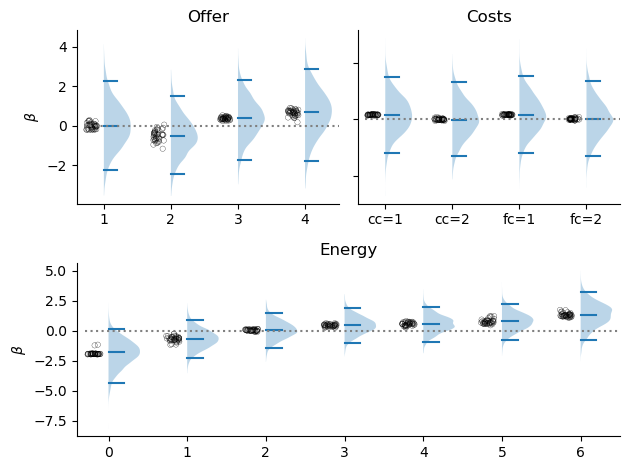

In [ ]:
# Plot task 1 parameters:
fig, ax = plt.subplot_mosaic("DDDEEE;FFFFFF")
# Plot the results
# ================================================
# fig-2D: Plot the preferences parameters of the preference model:
ylim = []
violinparts = []
width = 0.8

# ===========================
# Plot offer parameters:
data = []
for var in ["B_o_1", "B_o_2", "B_o_3", "B_o_4"]:
    vals = idata_task1.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["D"].violinplot(data, positions=range(len(data)), widths=width,
                    showmeans=False, showmedians=True,
                    showextrema=False, side="high", 
                    quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["D"].set_xticks(range(len(data)))
ax["D"].set_xticklabels([1, 2, 3, 4])
ax["D"].set_ylabel(r"$\beta$")
ax["D"].hlines(0, -0.3, 3.5, color='gray', linestyles=':')
ax["D"].set_xlim([-0.4, 3.5])
ax["D"].spines[['right', 'top']].set_visible(False)
ax["D"].set_title("Offer")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(["B_o_1", "B_o_2", "B_o_3", "B_o_4"]):
    vals = idata_task1.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["D"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
ylim.append(ax["D"].get_ylim())

# ===========================
# Plot Costs parameters:
data = []
for var in ["B_cc_1", "B_cc_2", "B_fc_1", "B_fc_2"]:
    vals = idata_task1.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["E"].violinplot(data, positions=range(len(data)), widths=width,
                    showmeans=False, showmedians=True,
                    showextrema=False, side="high",
                    quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["E"].set_xticks(range(len(data)))
ax["E"].set_xticklabels(['cc=1', 'cc=2', 'fc=1', 'fc=2'])
ax["E"].set_yticklabels([])
ax["E"].hlines(0, -0.3, 3.5, color='gray', linestyles=':')
ax["E"].set_xlim([-0.4, 3.5])
ax["E"].spines[['right', 'top']].set_visible(False)
ax["E"].set_title("Costs")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(["B_cc_1", "B_cc_2", "B_fc_1", "B_fc_2"]):
    vals = idata_task1.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["E"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
ylim.append(ax["D"].get_ylim())

# ===========================
# Plot energy parameters:
data = []
for var in ["B_e_0", "B_e_1", "B_e_2", "B_e_3", 
            "B_e_4", "B_e_5", "B_e_6"]:
    vals = idata_task1.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["F"].violinplot(data, positions=range(len(data)), widths=width, 
                     showmeans=False, showmedians=True,
                     showextrema=False, side="high",
                     quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["F"].set_xticks(range(len(data)))
ax["F"].set_xticklabels([0, 1, 2, 3, 4, 5, 6])
ax["F"].hlines(0, -0.3, 6.5, color='gray', linestyles=':')
ax["F"].set_xlim([-0.4, 6.5])
ax["F"].set_title('Energy')
ax["F"].spines[['right', 'top']].set_visible(False)
ax["F"].set_ylabel(r"$\beta$")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(["B_e_0", "B_e_1", "B_e_2", "B_e_3", "B_e_4", "B_e_5", "B_e_6"]):
    vals = idata_task1.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["F"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
plt.tight_layout()

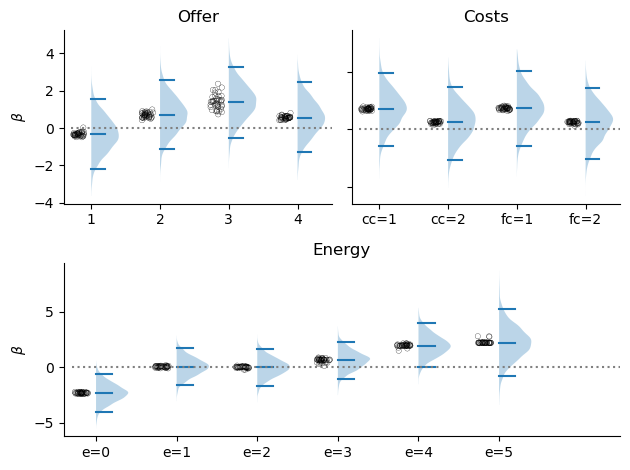

In [ ]:
# Plot task 2 parameters:
fig, ax = plt.subplot_mosaic("DDDEEE;FFFFFF")
# Plot the results
# ================================================
# fig-2D: Plot the preferences parameters of the preference model:
ylim = []
violinparts = []
width = 0.8

# ===========================
# Plot offer parameters:
data = []
for var in ['B_' + col for col in experiment2_data.columns if 'o_' in col]:
    vals = idata_task2.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["D"].violinplot(data, positions=range(len(data)), widths=width,
                    showmeans=False, showmedians=True,
                    showextrema=False, side="high", 
                    quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["D"].set_xticks(range(len(data)))
ax["D"].set_xticklabels([1, 2, 3, 4])
ax["D"].set_ylabel(r"$\beta$")
ax["D"].hlines(0, -0.3, 3.5, color='gray', linestyles=':')
ax["D"].set_xlim([-0.4, 3.5])
ax["D"].spines[['right', 'top']].set_visible(False)
ax["D"].set_title("Offer")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(['B_' + col for col in experiment2_data.columns if 'o_' in col]):
    vals = idata_task2.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["D"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
ylim.append(ax["D"].get_ylim())

# ===========================
# Plot Costs parameters:
data = []
for var in ['B_' + col for col in experiment2_data.columns if ('cc_' in col) or ('fc' in col)]:
    vals = idata_task2.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["E"].violinplot(data, positions=range(len(data)), widths=width,
                    showmeans=False, showmedians=True,
                    showextrema=False, side="high",
                    quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["E"].set_xticks(range(len(data)))
ax["E"].set_xticklabels(['cc=1', 'cc=2', 'fc=1', 'fc=2'])
ax["E"].set_yticklabels([])
ax["E"].hlines(0, -0.3, 3.5, color='gray', linestyles=':')
ax["E"].set_xlim([-0.4, 3.5])
ax["E"].spines[['right', 'top']].set_visible(False)
ax["E"].set_title("Costs")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(['B_' + col for col in experiment2_data.columns if ('cc_' in col) or ('fc' in col)]):
    vals = idata_task2.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["E"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
ylim.append(ax["D"].get_ylim())

# ===========================
# Plot energy parameters:
data = []
for var in ['B_' + col for col in experiment2_data.columns if 'e_' in col]:
    vals = idata_task2.posterior["beta_pref"].sel(coef_pref=var).values.flatten()
    data.append(vals)
prts = ax["F"].violinplot(data, positions=range(len(data)), widths=width, 
                     showmeans=False, showmedians=True,
                     showextrema=False, side="high",
                     quantiles=[[0.025, 0.975]]*len(data));
violinparts.append(prts)
ax["F"].set_xticks(range(len(data)))
ax["F"].set_xticklabels(['e=' + col[-1] for col in experiment2_data.columns if 'e_' in col])
ax["F"].hlines(0, -0.3, 6.5, color='gray', linestyles=':')
ax["F"].set_xlim([-0.4, 6.5])
ax["F"].set_title('Energy')
ax["F"].spines[['right', 'top']].set_visible(False)
ax["F"].set_ylabel(r"$\beta$")

# Plot the single participants fit:
data = []
positions = []
for i, var in enumerate(['B_' + col for col in experiment2_data.columns if 'e_' in col]):
    vals = idata_task2.posterior["beta_pref_sub"].sel(coef_pref=var).mean(dim=["chain", "draw"]).values
    data.append(vals)
    positions.append(np.random.uniform(low=i - (width*1/3), high=i-width*1/8, size=len(vals)))
ax["F"].scatter(positions, data, s=15, c='None', edgecolors="k", linewidth=0.2)
plt.tight_layout()